In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [15]:

sales = pd.read_csv("/content/sales.csv")
products = pd.read_csv("/content/products.csv")
stores = pd.read_csv("/content/stores.csv")
promotions = pd.read_csv("/content/promotions.csv")
calendar = pd.read_csv("/content/calendar.csv")

print("All five datasets loaded successfully!")
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)


All five datasets loaded successfully!
Sales: (78997, 6)
Products: (60, 4)
Stores: (12, 4)
Promotions: (5, 3)
Calendar: (365, 5)


In [16]:

for name, df in {
    "Sales": sales,
    "Products": products,
    "Stores": stores,
    "Promotions": promotions,
    "Calendar": calendar
}.items():

    print("\n==========", name, "==========")

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())



========== Sales ==========

Missing Values:
date           0
store          0
product        0
units          0
revenue        0
campaign    1185
dtype: int64

Duplicate Rows:
157

========== Products ==========

Missing Values:
product       0
category      0
brand         0
price band    0
dtype: int64

Duplicate Rows:
0

========== Stores ==========

Missing Values:
store         0
city          0
format        0
floor area    0
dtype: int64

Duplicate Rows:
0

========== Promotions ==========

Missing Values:
campaign    0
discount    0
duration    0
dtype: int64

Duplicate Rows:
0

========== Calendar ==========

Missing Values:
date        0
weekday     0
holiday     0
festival    0
season      0
dtype: int64

Duplicate Rows:
0


In [17]:

print("Zero units:", (sales["units"] == 0).sum())
print("Negative units:", (sales["units"] < 0).sum())
print("Negative revenue:", (sales["revenue"] < 0).sum())

display(sales.describe())


Zero units: 118
Negative units: 118
Negative revenue: 118


,units,revenue
count,78997.000000,78997.000000
mean,7.004481,3610.003576
std,4.182211,3259.622152
min,-1.000000,-17334.000000
25%,4.000000,1134.000000
50%,6.000000,2584.000000
75%,10.000000,5145.000000
max,34.000000,25952.200000


In [18]:

# Remove duplicate records from each dataset
sales = sales.drop_duplicates().copy()
products = products.drop_duplicates().copy()
stores = stores.drop_duplicates().copy()
promotions = promotions.drop_duplicates().copy()
calendar = calendar.drop_duplicates().copy()

print("Duplicate rows removed successfully!")

print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)


Duplicate rows removed successfully!
Sales: (78840, 6)
Products: (60, 4)
Stores: (12, 4)
Promotions: (5, 3)
Calendar: (365, 5)


In [19]:

# Remove extra spaces and standardize category names
products["category"] = (
    products["category"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Display category counts
print(products["category"].value_counts(dropna=False))



category
personal care    20
dairy            12
beverages         9
grocery           8
household         6
snacks            5
Name: count, dtype: Int64


In [20]:

# Identify invalid sales records
invalid_mask = (
    sales["units"].isna()
    | sales["revenue"].isna()
    | (sales["units"] <= 0)
    | (sales["revenue"] < 0)
)

invalid_sales = sales[invalid_mask].copy()

# Keep a copy of invalid records for evidence
invalid_sales.to_csv(
    "/content/invalid_sales_audit.csv",
    index=False
)

print("Invalid records identified:", len(invalid_sales))

# Retain valid positive-sales records for analysis
sales = sales[~invalid_mask].copy()

print("Remaining sales records:", len(sales))
print("Invalid records saved for audit.")



Invalid records identified: 236
Remaining sales records: 78604
Invalid records saved for audit.


In [21]:

for name, df in {
    "Sales": sales,
    "Products": products,
    "Stores": stores,
    "Promotions": promotions,
    "Calendar": calendar
}.items():
    print("\n", name)
    print(df.isnull().sum())



 Sales
date           0
store          0
product        0
units          0
revenue        0
campaign    1180
dtype: int64

 Products
product       0
category      0
brand         0
price band    0
dtype: int64

 Stores
store         0
city          0
format        0
floor area    0
dtype: int64

 Promotions
campaign    0
discount    0
duration    0
dtype: int64

 Calendar
date        0
weekday     0
holiday     0
festival    0
season      0
dtype: int64


In [22]:

# Convert date columns to datetime
sales["date"] = pd.to_datetime(sales["date"], errors="coerce")
calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")

# Merge sales with product details
df = sales.merge(
    products,
    on="product",
    how="left",
    validate="many_to_one"
)

# Merge store details
df = df.merge(
    stores,
    on="store",
    how="left",
    validate="many_to_one"
)

# Merge calendar details
df = df.merge(
    calendar,
    on="date",
    how="left",
    validate="many_to_one"
)

print("Datasets merged successfully!")
print("Combined dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())


Datasets merged successfully!
Combined dataset shape: (78604, 16)


,date,store,product,units,revenue,campaign,category,brand,price band,city,format,floor area,weekday,holiday,festival,season
0,2025-01-01,S001,P022,5,535.5,Festival Offer,dairy,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
1,2025-01-01,S001,P019,1,268.6,Festival Offer,household,FreshChoice,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
2,2025-01-01,S001,P047,4,1598.0,Festival Offer,household,SunPeak,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
3,2025-01-01,S001,P051,8,1482.4,Festival Offer,snacks,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
4,2025-01-01,S001,P034,2,212.5,Festival Offer,dairy,DailyFarm,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter



Columns:
['date', 'store', 'product', 'units', 'revenue', 'campaign', 'category', 'brand', 'price band', 'city', 'format', 'floor area', 'weekday', 'holiday', 'festival', 'season']


In [23]:

df = df.merge(
    promotions,
    on="campaign",
    how="left",
    validate="many_to_one",
    suffixes=("", "_promotion")
)

print("Promotion data merged!")
print("Final dataset shape:", df.shape)
display(df.head())


Promotion data merged!
Final dataset shape: (78604, 18)


,date,store,product,units,revenue,campaign,category,brand,price band,city,format,floor area,weekday,holiday,festival,season,discount,duration
0,2025-01-01,S001,P022,5,535.5,Festival Offer,dairy,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
1,2025-01-01,S001,P019,1,268.6,Festival Offer,household,FreshChoice,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
2,2025-01-01,S001,P047,4,1598.0,Festival Offer,household,SunPeak,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
3,2025-01-01,S001,P051,8,1482.4,Festival Offer,snacks,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
4,2025-01-01,S001,P034,2,212.5,Festival Offer,dairy,DailyFarm,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0


In [24]:

# Extract date-based features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["quarter"] = df["date"].dt.quarter
df["day_of_week"] = df["date"].dt.dayofweek
df["weekend"] = (df["day_of_week"] >= 5).astype(int)

print("New features created successfully!")
display(df.head())


New features created successfully!


,date,store,product,units,revenue,campaign,category,brand,price band,city,...,festival,season,discount,duration,year,month,month_name,quarter,day_of_week,weekend
0,2025-01-01,S001,P022,5,535.5,Festival Offer,dairy,HomeEase,Mid-range,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
1,2025-01-01,S001,P019,1,268.6,Festival Offer,household,FreshChoice,Budget,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
2,2025-01-01,S001,P047,4,1598.0,Festival Offer,household,SunPeak,Budget,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
3,2025-01-01,S001,P051,8,1482.4,Festival Offer,snacks,HomeEase,Mid-range,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
4,2025-01-01,S001,P034,2,212.5,Festival Offer,dairy,DailyFarm,Mid-range,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0


In [25]:

df.to_csv("/content/freshcart_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [26]:

from google.colab import files
files.download("/content/freshcart_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Revenue by Product Category:


,category,revenue
0,personal care,85562408.15
1,dairy,51252491.45
2,beverages,48658510.55
3,grocery,36521149.70
4,snacks,34012890.40
5,household,28997618.80


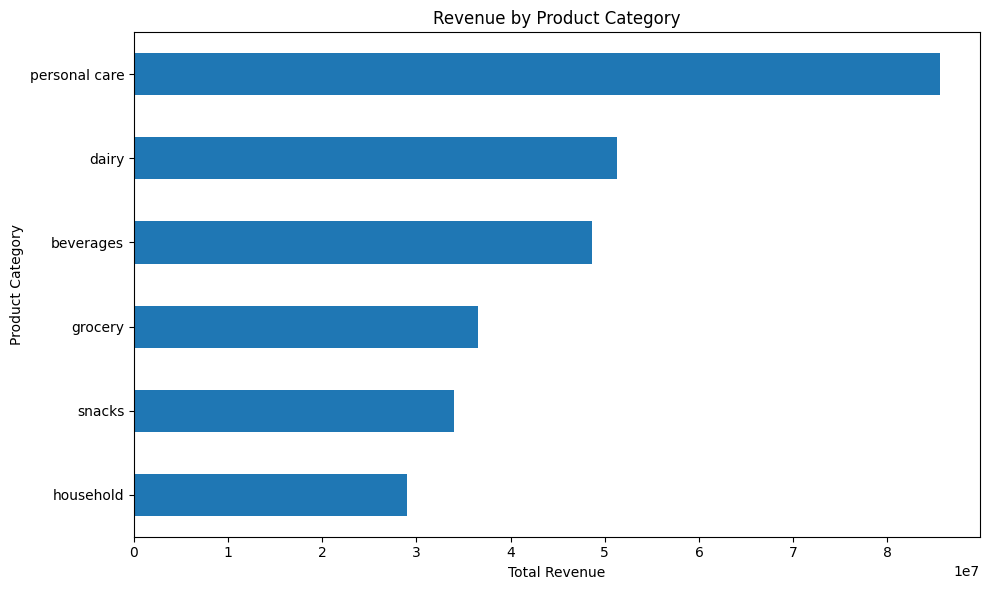

In [28]:

# Revenue by product category

category_revenue = (
    df.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Category:")
display(category_revenue.reset_index())

# Create a bar chart
plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


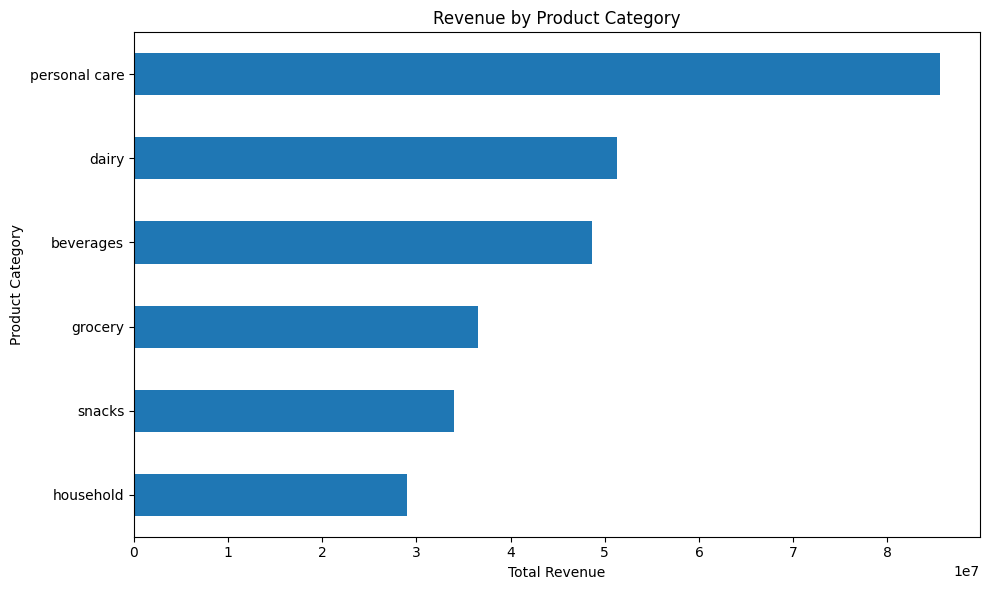

In [29]:

plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(kind="barh")

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "/content/category_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [32]:

# Calculate monthly revenue for each store
df["date"] = pd.to_datetime(df["date"])

monthly_store = (
    df.groupby([
        "store",
        pd.Grouper(key="date", freq="MS")
    ])["revenue"]
    .sum()
    .reset_index()
)

monthly_store.columns = [
    "store", "month", "monthly_revenue"
]

display(monthly_store.head(10))


,store,month,monthly_revenue
0,S001,2025-01-01,1556775.65
1,S001,2025-02-01,1292691.30
2,S001,2025-03-01,1463919.50
3,S001,2025-04-01,1446768.50
4,S001,2025-05-01,1457606.80
5,S001,2025-06-01,1339998.40
6,S001,2025-07-01,1466823.70
7,S001,2025-08-01,1533357.55
8,S001,2025-09-01,1383229.00
9,S001,2025-10-01,1437792.90


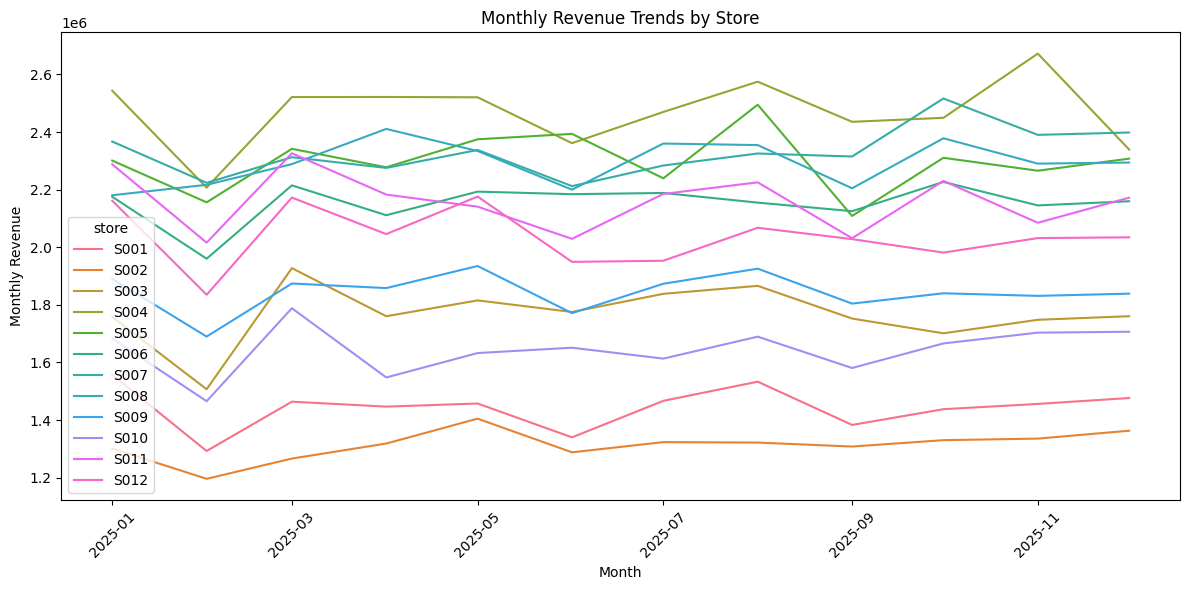

In [33]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_store,
    x="month",
    y="monthly_revenue",
    hue="store",
    estimator="sum",
    errorbar=None
)

plt.title("Monthly Revenue Trends by Store")
plt.xlabel("Month")
plt.ylabel("Monthly Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [34]:

store_growth = (
    monthly_store.sort_values("month")
    .groupby("store")
    .agg(
        first_revenue=("monthly_revenue", "first"),
        last_revenue=("monthly_revenue", "last")
    )
)

store_growth["growth_percent"] = np.where(
    store_growth["first_revenue"] > 0,
    (
        (store_growth["last_revenue"] -
         store_growth["first_revenue"])
        / store_growth["first_revenue"]
    ) * 100,
    np.nan
)

store_growth = store_growth.sort_values(
    "growth_percent", ascending=False
)

display(store_growth)


,first_revenue,last_revenue,growth_percent
store,,,
S008,2180707.15,2294243.7,5.206410
S002,1301286.40,1363081.0,4.748732
S010,1683261.35,1706730.8,1.394284
S007,2367191.80,2398524.1,1.323606
S005,2300957.10,2307846.5,0.299415
S003,1758051.35,1760703.3,0.150846
S006,2175451.70,2159822.0,-0.718458
S009,1890290.20,1838978.2,-2.714504
S011,2288017.15,2172247.6,-5.059820


In [35]:

# Analyze sales by promotion campaign

promotion_summary = (
    df.groupby("campaign", dropna=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum"),
        average_revenue=("revenue", "mean"),
        sales_records=("revenue", "count")
    )
    .sort_values("total_revenue", ascending=False)
)

display(promotion_summary)


,total_revenue,total_units,average_revenue,sales_records
campaign,,,,
No Promotion,1.821452e+08,338190,3519.985448,51746
Weekend Deal,8.044264e+07,166496,3754.966321,21423
Festival Offer,1.797838e+07,39383,4225.235934,4255
NaN,4.438880e+06,8289,3761.762415,1180


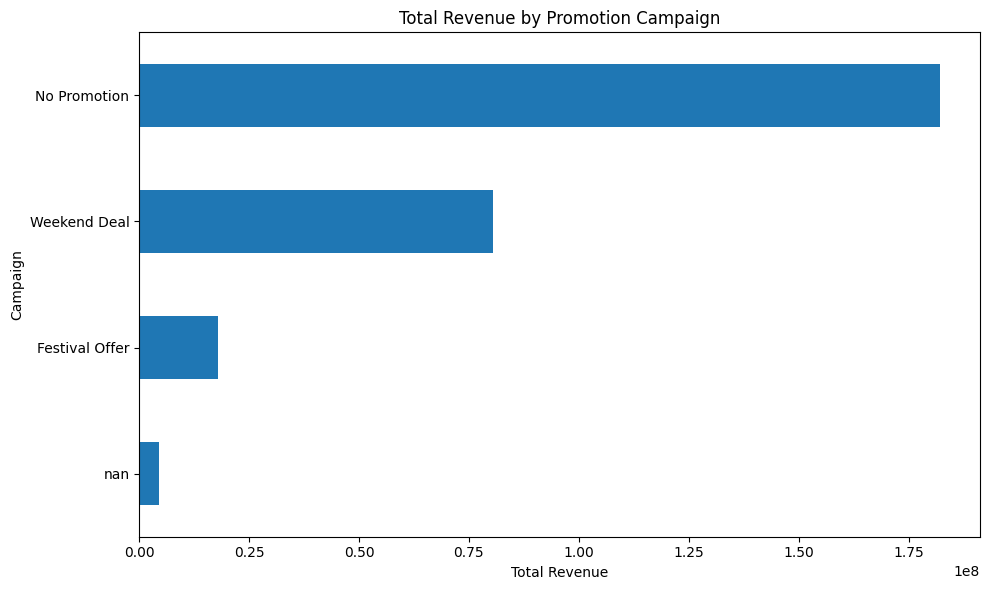

In [36]:

plt.figure(figsize=(10, 6))

promotion_summary["total_revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Total Revenue by Promotion Campaign")
plt.xlabel("Total Revenue")
plt.ylabel("Campaign")
plt.tight_layout()
plt.show()


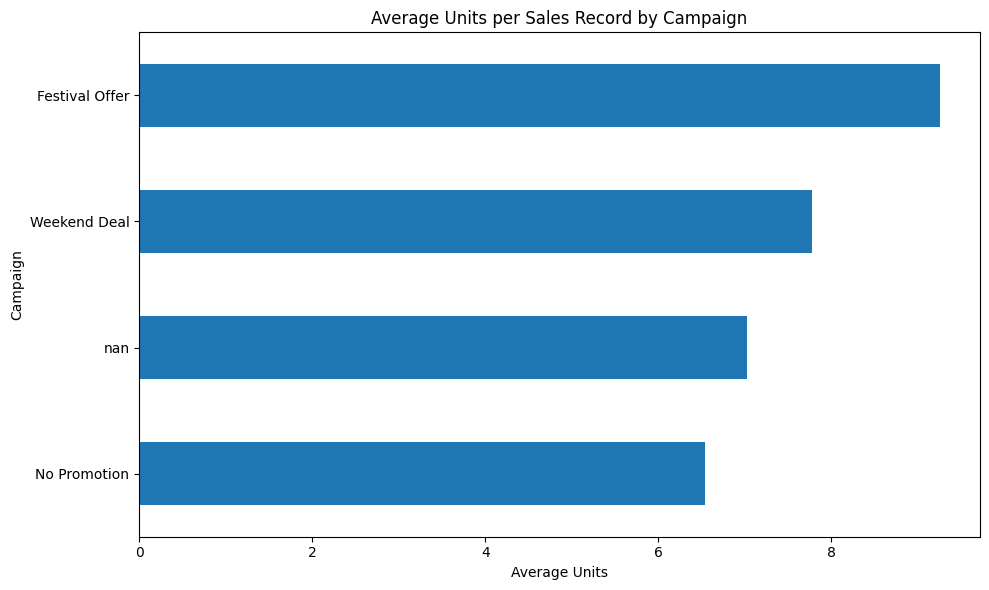

In [37]:

plt.figure(figsize=(10, 6))

promotion_summary["total_units"].div(
    promotion_summary["sales_records"].replace(0, np.nan)
).sort_values().plot(kind="barh")

plt.title("Average Units per Sales Record by Campaign")
plt.xlabel("Average Units")
plt.ylabel("Campaign")
plt.tight_layout()
plt.show()


In [38]:

# Compare sales during festival and non-festival periods

festival_summary = (
    df.groupby("festival", dropna=False)
    .agg(
        total_units=("units", "sum"),
        average_units=("units", "mean"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

display(festival_summary)


,festival,total_units,average_units,total_revenue
0,Festival Period,39858,9.254237,1.821702e+07
1,No Festival,512500,6.897990,2.667881e+08


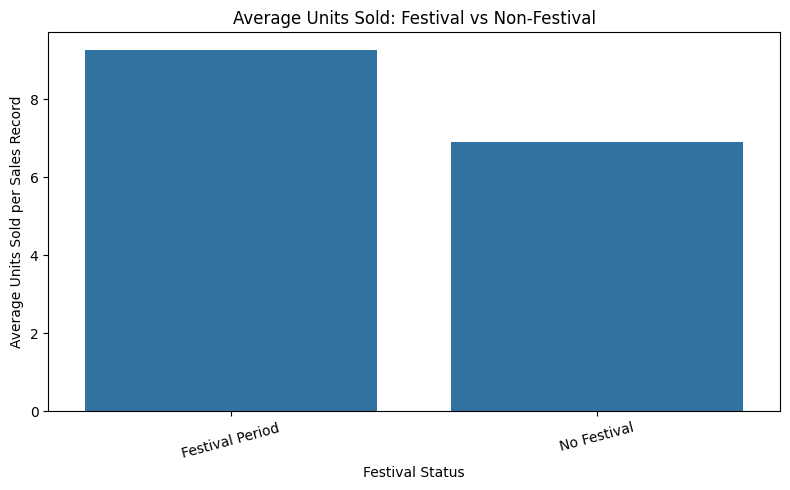

In [39]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=festival_summary,
    x="festival",
    y="average_units"
)

plt.title("Average Units Sold: Festival vs Non-Festival")
plt.xlabel("Festival Status")
plt.ylabel("Average Units Sold per Sales Record")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


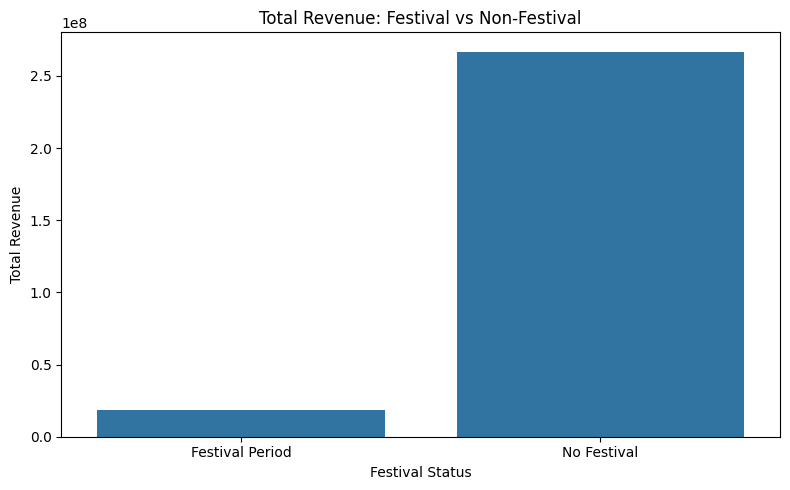

In [40]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=festival_summary,
    x="festival",
    y="total_revenue"
)

plt.title("Total Revenue: Festival vs Non-Festival")
plt.xlabel("Festival Status")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


In [41]:

# Product demand by season

seasonal_sales = (
    df.groupby(["product", "season"])
    .agg(
        total_units=("units", "sum"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

display(seasonal_sales.head(15))


,product,season,total_units,total_revenue
0,P001,Monsoon,2454,1299616.15
1,P001,Post-Monsoon,1501,784541.35
2,P001,Summer,2110,1113130.20
3,P001,Winter,1704,905623.60
4,P002,Monsoon,1512,705212.20
5,P002,Post-Monsoon,825,377810.40
6,P002,Summer,1081,503384.20
7,P002,Winter,1264,587382.40
8,P003,Monsoon,3771,2944294.95
9,P003,Post-Monsoon,2157,1652655.80


In [42]:

# Find the season with the highest units sold for each product

product_season = (
    seasonal_sales.sort_values("total_units", ascending=False)
    .drop_duplicates(subset="product")
    .sort_values("total_units", ascending=False)
)

print("Top 15 product-season combinations:")
display(product_season.head(15))


Top 15 product-season combinations:


,product,season,total_units,total_revenue
184,P047,Monsoon,4990,2261922.00
60,P016,Monsoon,4868,4200035.80
128,P033,Monsoon,4837,1551246.30
44,P012,Monsoon,4795,189823.85
156,P040,Monsoon,4763,255304.00
192,P049,Monsoon,4591,4264404.75
148,P038,Monsoon,4532,1068445.00
216,P055,Monsoon,4516,2732281.65
236,P060,Monsoon,4485,4035799.55
16,P005,Monsoon,4484,4108353.30


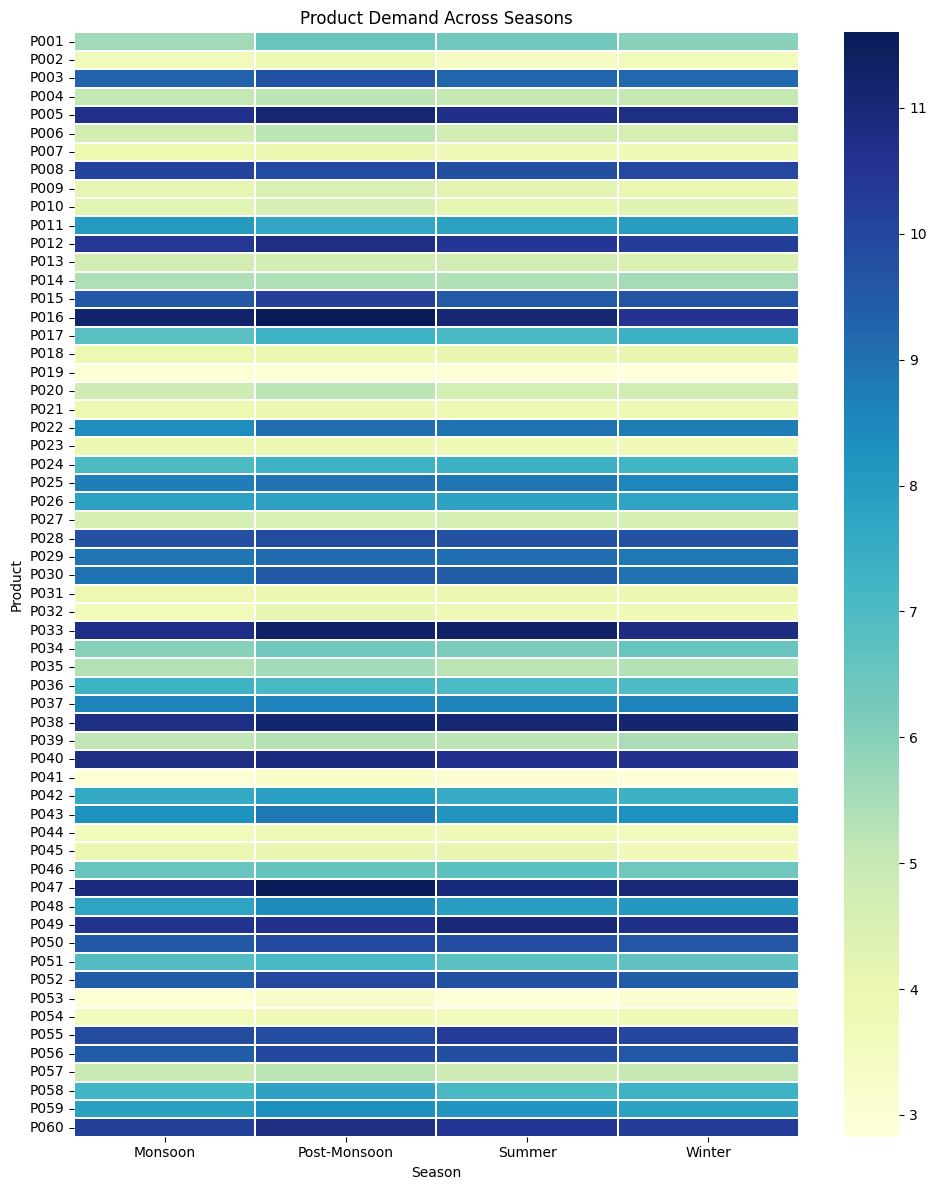

In [43]:

# Average units sold per product in each season

season_pivot = df.pivot_table(
    index="product",
    columns="season",
    values="units",
    aggfunc="mean"
)

plt.figure(figsize=(10, 12))

sns.heatmap(
    season_pivot,
    cmap="YlGnBu",
    linewidths=0.2
)

plt.title("Product Demand Across Seasons")
plt.xlabel("Season")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


,total_revenue,total_units
weekday_name,,
Monday,39344941.35,74744
Tuesday,40177918.05,75472
Wednesday,40470856.85,76375
Thursday,39971660.85,74416
Friday,40055269.95,75088
Saturday,42355014.10,88180
Sunday,42629407.90,88083


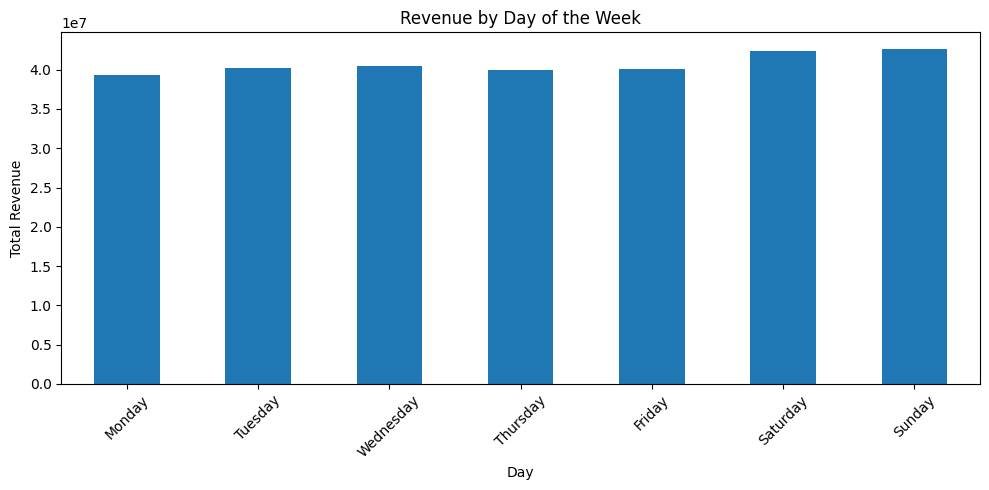

In [47]:

# Create weekday_name from the date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["weekday_name"] = df["date"].dt.day_name()

# Total revenue and units by weekday
weekday_sales = (
    df.groupby("weekday_name")
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum")
    )
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

display(weekday_sales)

# Plot revenue by weekday
weekday_sales["total_revenue"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,total_revenue,total_units
weekday_name,,
Monday,39344941.35,74744
Tuesday,40177918.05,75472
Wednesday,40470856.85,76375
Thursday,39971660.85,74416
Friday,40055269.95,75088
Saturday,42355014.10,88180
Sunday,42629407.90,88083


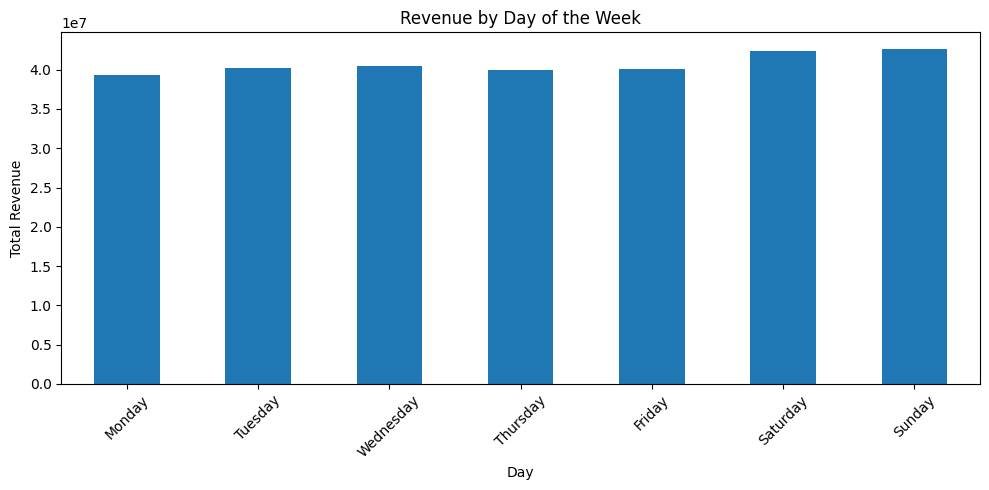

In [50]:
# Total revenue by day of the week

weekday_sales = (
    df.groupby("weekday_name")
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum")
    )
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

display(weekday_sales)

weekday_sales["total_revenue"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:

# Convert date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Create month features if they don't exist
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

# Calculate monthly sales
monthly_sales = (
    df.groupby(["month", "month_name"])
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum")
    )
    .reset_index()
    .sort_values("month")
)

display(monthly_sales)


,month,month_name,total_revenue,total_units
0,1,January,24207506.95,47764
1,2,February,21767036.00,41322
2,3,March,24499542.40,46750
3,4,April,23758722.90,46855
4,5,May,24324441.10,46462
5,6,June,23156799.20,44302
6,7,July,23796263.60,45888
7,8,August,24535856.15,48486
8,9,September,23079056.90,44104
9,10,October,24070331.00,47316


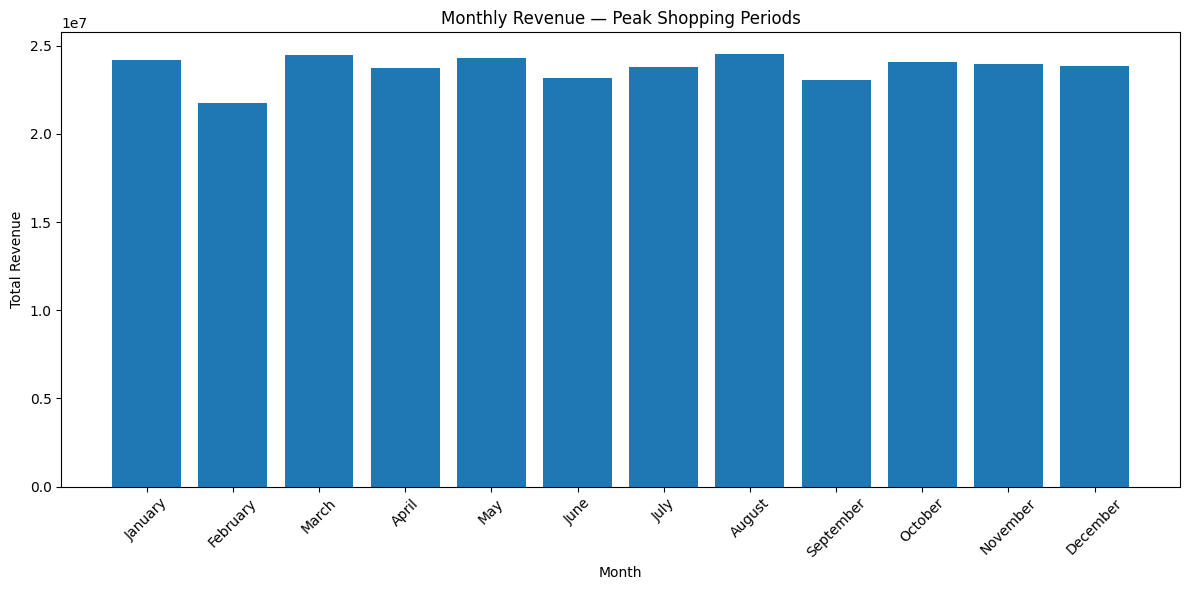

In [52]:

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_sales["month_name"],
    monthly_sales["total_revenue"]
)

plt.title("Monthly Revenue — Peak Shopping Periods")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [53]:

peak_month = monthly_sales.loc[
    monthly_sales["total_revenue"].idxmax()
]

print("Peak Revenue Month:", peak_month["month_name"])
print("Total Revenue:", round(peak_month["total_revenue"], 2))

peak_units_month = monthly_sales.loc[
    monthly_sales["total_units"].idxmax()
]

print("Peak Units Month:", peak_units_month["month_name"])
print("Total Units:", int(peak_units_month["total_units"]))


Peak Revenue Month: August
Total Revenue: 24535856.15
Peak Units Month: August
Total Units: 48486


In [54]:

from sklearn.preprocessing import LabelEncoder

# Create a separate dataset for feature engineering
feature_df = df.copy()

# Select categorical columns
categorical_cols = feature_df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

# Encode categorical variables
label_encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()

    feature_df[col] = encoder.fit_transform(
        feature_df[col].fillna("Unknown").astype(str)
    )

    label_encoders[col] = encoder

print("\nCategorical encoding completed!")
display(feature_df.head())


Categorical columns: ['store', 'product', 'campaign', 'category', 'brand', 'price band', 'city', 'format', 'weekday', 'festival', 'season', 'month_name', 'weekday_name']

Categorical encoding completed!


,date,store,product,units,revenue,campaign,category,brand,price band,city,...,season,discount,duration,year,month,month_name,quarter,day_of_week,weekend,weekday_name
0,2025-01-01,0,21,5,535.5,0,1,2,1,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
1,2025-01-01,0,18,1,268.6,0,3,1,0,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
2,2025-01-01,0,46,4,1598.0,0,3,4,0,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
3,2025-01-01,0,50,8,1482.4,0,5,2,1,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
4,2025-01-01,0,33,2,212.5,0,1,0,1,1,...,3,15.0,7.0,2025,1,4,1,2,0,6


In [56]:
import os

# Create output folder
os.makedirs("/content/freshcart_outputs", exist_ok=True)

# Save cleaned dataset
df.to_csv(
    "/content/freshcart_outputs/freshcart_cleaned.csv",
    index=False
)

# Save analysis tables
category_revenue.to_csv(
    "/content/freshcart_outputs/category_revenue.csv"
)

monthly_sales.to_csv(
    "/content/freshcart_outputs/monthly_sales.csv",
    index=False
)

weekday_sales.to_csv(
    "/content/freshcart_outputs/weekday_sales.csv"
)

print("All existing analysis files saved successfully!")

All existing analysis files saved successfully!


In [57]:

import shutil

shutil.make_archive(
    "/content/FreshCart_Round2_Results",
    "zip",
    "/content/freshcart_outputs"
)

print("ZIP file created successfully!")


ZIP file created successfully!


In [58]:

from google.colab import files

files.download("/content/FreshCart_Round2_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ROUND 3

In [59]:
from google.colab import files
files.download("/content/freshcart_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>